In [117]:
import numpy as np
import matplotlib.pyplot as plt
import mne
import pandas as pd
from pathlib import Path

Fs = 500
DATA_FOLDER = Path("data/calculia")
RESULTS_FOLDER = Path("results")

# Channel names
CHANNELS = {
    "ANT_FRONTAL" : ["Fp1", "Fp2"],
    "FRONTAL" : ["F3", "F4", "Fz", "F7", "F8"],
    "CENTRAL" : ["C3", "C4", "Cz"],
    "PARIETAL" : ["P3", "P4", "Pz"],
    "OCCIPITAL" : ["O1", "O2"],
    "TEMPORAL" : ["T3", "T4", "T5", "T6"],
}

all_channels = []
for chs in CHANNELS.values():
    all_channels += chs
CHANNELS["ALL_CHANNELS"] = all_channels
CHANNELS["ALL_FRONTAL"] = CHANNELS["ANT_FRONTAL"] + CHANNELS["FRONTAL"]

In [118]:
import matplotlib.font_manager as fm

BG_COLOR = "#f5f5f0"
CAPTION_COLOR = "#222222"
SUPPORT_COLOR = "#666666"

INTER_FONT_PATH = "data\\font\\Inter-Regular.ttf"   # a list of .ttf paths
fm.fontManager.addfont(INTER_FONT_PATH)
plt.rcParams.update({
    "figure.facecolor": BG_COLOR,
    "axes.facecolor": BG_COLOR,
    "text.color": CAPTION_COLOR,
    "axes.labelcolor": SUPPORT_COLOR,
    "xtick.color": SUPPORT_COLOR,
    "ytick.color": SUPPORT_COLOR,
    "figure.dpi": 110,
    "savefig.dpi": 600,
    "font.family": ["Inter", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [119]:
from _functions import PCE_by_band

PCEs = []

for sbj_id in range(36):
    sbj = f"Subject{sbj_id:02d}"
    rest_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_1.edf", verbose=False)
    calc_raw = mne.io.read_raw_edf(DATA_FOLDER / f"Subject{sbj_id:02d}_2.edf", verbose=False)


    for name, channels in CHANNELS.items():           
        rest_np = np.array(rest_raw[["EEG " + ch for ch in channels]][0])
        rest = PCE_by_band(rest_np, Fs = Fs)
        for result in rest:
            PCEs.append({
                "Subject" : sbj,
                "Location" : name,
                "Band" : result["band"],
                "Rest" : 1,
                "PCE" : result["PCE"]
            }) 

        calc_np = np.array(calc_raw[["EEG " + ch for ch in channels]][0])
        calc = PCE_by_band(calc_np, Fs = Fs)
        for result in calc:
                PCEs.append({
                    "Subject" : sbj,
                    "Location" : name,
                    "Band" : result["band"],
                    "Rest" : 0,
                    "PCE" : result["PCE"]
                }) 


df_results = pd.DataFrame(PCEs)
df_results.head()

,Subject,Location,Band,Rest,PCE
0,Subject00,ANT_FRONTAL,delta,1,0.271118
1,Subject00,ANT_FRONTAL,theta,1,0.209871
2,Subject00,ANT_FRONTAL,alpha,1,0.104924
3,Subject00,ANT_FRONTAL,beta,1,0.207345
4,Subject00,ANT_FRONTAL,gamma,1,0.301815


## Merge user Information

In [120]:
user_df = pd.read_csv(DATA_FOLDER / "subject-info.csv")
df = df_results.merge(user_df, on = "Subject")
df["Male"] = df.Gender.map({"M" : 1, "F" : 0})
df = df.drop(columns=["Recording year", "Number of subtractions", "Gender"])

In [121]:
# fig, axes = plt.subplots(2, 1, figsize = (15, 8), facecolor = BG_COLOR)
# barWidth = 0.25

# br1 = np.arange(df.Location.nunique()) 
# br2 = [x + barWidth for x in br1] 

# data = df[good_counters_mask].groupby("Location")["PCE"].mean()
# axes[0].barh(br1, data.values)#, width = barWidth)
# data = df[~good_counters_mask].groupby("Location")["PCE"].mean()
# axes[0].barh(br2, data.values)#, width = barWidth)
# axes[0].set_yticklabels(data.index)

# data = df[good_counters_mask].groupby("Band")["PCE"].mean()
# axes[1].barh(data.index, data.values)
# data = df[~good_counters_mask].groupby("Band")["PCE"].mean()
# axes[1].barh(data.index, data.values)

## Recognize good vs bad counters

In [122]:
from scipy.stats import mannwhitneyu
from _functions import cohen_d

res = []
ttest = []

for rest in [0, 1, 2]:
    rest_mask = df["Rest"] == rest
    df_rest = df.loc[rest_mask, :]
    
    if rest == 2:
        df_rest = df[df["Rest"] == 0].copy()
        df_rest["PCE"] = df_rest["PCE"].values -df.loc[df["Rest"] == 1, "PCE"].values # type: ignore

    
    good_counters_mask = df_rest["Count quality"] == 1
        
    for ch in list(CHANNELS.keys()):
        channel_mask = df_rest["Location"] == ch
        for band in df_rest["Band"].unique():
            band_mask = df_rest["Band"] == band
            good_counters = df_rest.loc[good_counters_mask & channel_mask & band_mask,
                                   "PCE"].values
            bad_counters = df_rest.loc[~good_counters_mask & channel_mask & band_mask,
                                   "PCE"].values
            _, p = mannwhitneyu(good_counters, bad_counters)
            effect_size = cohen_d(good_counters, bad_counters)

            res.append({
                "Location" : ch,
                "Band" : band,
                "Rest" : rest,
                "p" : p,
                "cohen_d" : effect_size
            })

df_comparisons = pd.DataFrame(res)
df_comparisons["log_p"] = -np.log10(df_comparisons["p"])
df_comparisons.to_csv(RESULTS_FOLDER / "good vs bad counters.csv")

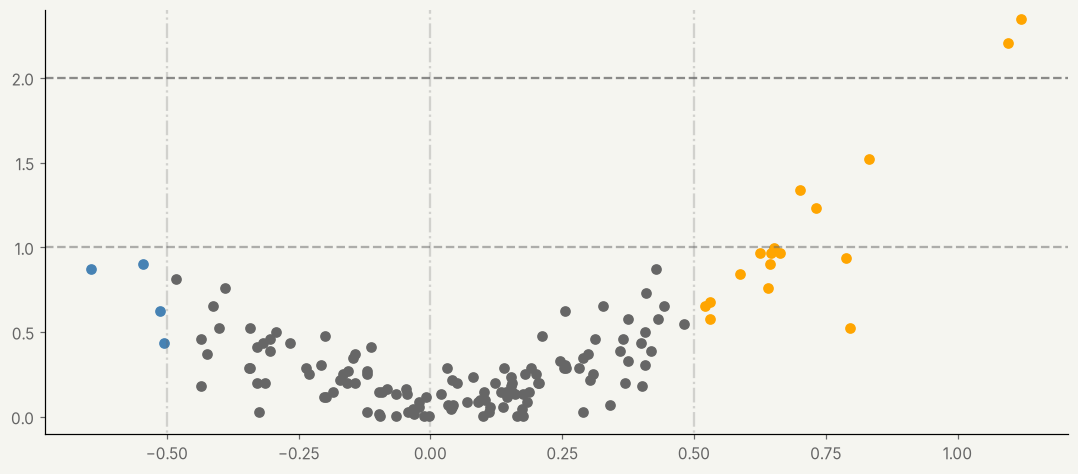

In [123]:
fig, ax = plt.subplots(figsize=(12, 5))

blue_mask = df_comparisons["cohen_d"] < -0.5
red_mask = df_comparisons["cohen_d"] > 0.5
gray_mask = ~(blue_mask | red_mask)

ax.scatter(df_comparisons.loc[gray_mask, "cohen_d"], df_comparisons.loc[gray_mask, "log_p"], color = SUPPORT_COLOR)
ax.scatter(df_comparisons.loc[blue_mask, "cohen_d"], df_comparisons.loc[blue_mask, "log_p"], color = "steelblue")
ax.scatter(df_comparisons.loc[red_mask, "cohen_d"], df_comparisons.loc[red_mask, "log_p"], color = "orange")

# ax.set_xlim(-1, 1)
ax.set_ylim(-0.1, 2.4)
ax.vlines([-0.5, 0, 0.5], ymin=-0.2, ymax=2.5, colors=SUPPORT_COLOR, alpha = 0.25, linestyles="-.")
ax.axhline(-np.log10(0.01), label = "p = 0.01", color=SUPPORT_COLOR, alpha = 0.75, linestyle="--")
ax.axhline(-np.log10(0.1), label = "p = 0.1", color=SUPPORT_COLOR, alpha = 0.5, linestyle="--")

plt.show()

In [124]:
df_comparisons.loc[blue_mask | red_mask, :].sort_values(by="p")

,Location,Band,Rest,p,cohen_d,log_p
5,ANT_FRONTAL,all,0,0.004467,1.121086,2.349976
0,ANT_FRONTAL,delta,0,0.006197,1.096273,2.207842
42,ALL_FRONTAL,delta,0,0.029849,0.832331,1.525074
95,ALL_FRONTAL,all,1,0.045988,0.700384,1.337351
90,ALL_FRONTAL,delta,1,0.058819,0.731108,1.230482
129,TEMPORAL,beta,2,0.100525,0.652050,0.997726
53,ANT_FRONTAL,all,1,0.108055,0.624566,0.966353
36,ALL_CHANNELS,delta,0,0.108055,0.663547,0.966353
47,ALL_FRONTAL,all,0,0.108055,0.646435,0.966353
78,TEMPORAL,delta,1,0.116026,0.788187,0.935446


In [125]:
from scipy.stats import ttest_rel

df_increase = df[df["Rest"] == 0].copy()
df_increase["PCE_calc"] = df_increase["PCE"].values
df_increase["PCE_rest"] = df.loc[df["Rest"] == 1, "PCE"].values # type: ignore
df_increase = df_increase.drop(columns = ["PCE"])

res = []

for ch in df_increase["Location"].unique():
    channel_mask = df_increase["Location"] == ch
    for band in df_increase["Band"].unique():
        band_mask = df_increase["Band"] == band
        
        for good_counters in [0, 1, 2]:
            counters_mask = df_increase["Count quality"] == good_counters
            if good_counters == 2:
                counters_mask = df_increase["Count quality"] < 2
                 
            df_case = df_increase.loc[channel_mask & band_mask & counters_mask, :]
            _, p = ttest_rel(df_case["PCE_calc"], df_case["PCE_rest"], alternative="greater")
            effect_size = cohen_d(df_case["PCE_calc"].values, df_case["PCE_rest"].values)

            res.append({
                    "Location" : ch,
                    "Band" : band,
                    "n" : len(df_case),
                    "Counters" : "Good" if good_counters == 1 else "Poor" if good_counters == 0 else "All",
                    "p" : p,
                    "cohen_d" : effect_size
                    })

df_ttest = pd.DataFrame(res)
df_ttest["log_p"] = -np.log10(df_ttest["p"])
df_ttest.to_csv(RESULTS_FOLDER / "ttest.csv")
df_ttest[df_ttest["p"] < 0.01]

,Location,Band,n,Counters,p,cohen_d,log_p
7,ANT_FRONTAL,alpha,26,Good,2.655811e-05,0.772766,4.575803
8,ANT_FRONTAL,alpha,36,All,5.174583e-06,0.679953,5.286125
10,ANT_FRONTAL,beta,26,Good,7.251646e-03,0.513000,2.139563
11,ANT_FRONTAL,beta,36,All,4.410764e-03,0.458590,2.355486
22,FRONTAL,theta,26,Good,1.176323e-03,0.785907,2.929473
23,FRONTAL,theta,36,All,5.513231e-05,0.870768,4.258594
24,FRONTAL,alpha,10,Poor,9.381198e-03,0.857204,2.027742
25,FRONTAL,alpha,26,Good,1.504815e-04,0.777811,3.822517
26,FRONTAL,alpha,36,All,6.328743e-06,0.791764,5.198683
28,FRONTAL,beta,26,Good,8.280739e-05,0.621632,4.081931


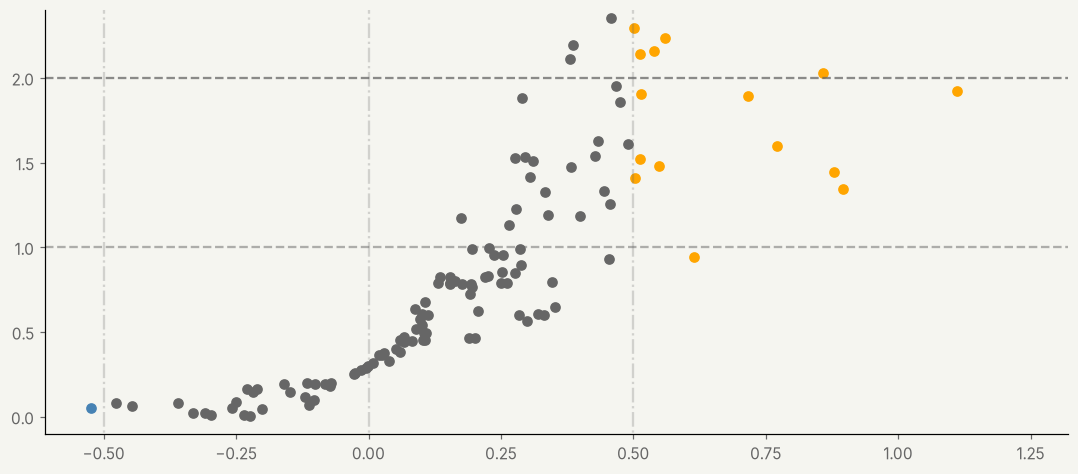

In [126]:
fig, ax = plt.subplots(figsize=(12, 5))

blue_mask = df_ttest["cohen_d"] < -0.5
red_mask = df_ttest["cohen_d"] > 0.5
gray_mask = ~(blue_mask | red_mask)

ax.scatter(df_ttest.loc[gray_mask, "cohen_d"], df_ttest.loc[gray_mask, "log_p"], color = SUPPORT_COLOR)
ax.scatter(df_ttest.loc[blue_mask, "cohen_d"], df_ttest.loc[blue_mask, "log_p"], color = "steelblue")
ax.scatter(df_ttest.loc[red_mask, "cohen_d"], df_ttest.loc[red_mask, "log_p"], color = "orange")

# ax.set_xlim(-1, 1)
ax.set_ylim(-0.1, 2.4)
ax.vlines([-0.5, 0, 0.5], ymin=-0.2, ymax=2.5, colors=SUPPORT_COLOR, alpha = 0.25, linestyles="-.")
ax.axhline(-np.log10(0.01), label = "p = 0.01", color=SUPPORT_COLOR, alpha = 0.75, linestyle="--")
ax.axhline(-np.log10(0.1), label = "p = 0.1", color=SUPPORT_COLOR, alpha = 0.5, linestyle="--")

plt.show()